# COVID-19 Detection on Chest X-ray Images Using Deep Learning

## Task 1.1 - Classificazione Multi-Classe

Dataset: COVID-19 Radiography Database


## Che cos'è il COVID-19?

Il COVID-19 è una malattia respiratoria causata dal virus SARS-CoV-2. La diagnosi tramite radiografia toracica può mostrare:

- **Opacità a vetro smerigliato** (ground-glass opacities)
- **Consolidamenti polmonari bilaterali**
- **Pattern interstiziale diffuso**

La polmonite virale tradizionale presenta pattern simili ma con alcune differenze nella distribuzione e nell'aspetto delle lesioni.


## Che cos'è una CNN (Convolutional Neural Network)?

CNN è l'acronimo di Convolutional Neural Network, una rete neurale specializzata nell'elaborazione di dati che hanno una struttura in ingresso simile a una matrice 2D, come le immagini. Le CNN sono tipicamente utilizzate per il rilevamento e la classificazione di immagini.

## A. COMPRENSIONE DEL TASK

### Contesto

Il nostro obiettivo è classificare le radiografie toraciche in **3 classi**:
- **Normal** (Sano)
- **Viral Pneumonia** (Polmonite Virale)
- **COVID-19**

### Contenuto del dataset

Il dataset contiene immagini PNG di radiografie toraciche suddivise in 3 cartelle:
- Normal: ~5000 immagini
- Viral Pneumonia: ~1345 immagini
- COVID: ~3616 immagini

**Totale: ~9961 immagini**

### Metodologia

Utilizzeremo la **Nested K-Fold Cross-Validation** (3 outer fold × 3 inner fold) per:
1. Ottimizzare gli iperparametri (inner loop)
2. Valutare le performance finali (outer loop)


## B. COMPRENSIONE DEL DATASET

### Installazione delle Librerie

In [1]:
!pip install gdown --upgrade --quiet

In [ ]:
# Import libraries
import os
from os import listdir, makedirs, getcwd, remove
from os.path import isfile, join, abspath, exists, isdir, expanduser
import gdown
import zipfile

import warnings
warnings.filterwarnings('ignore', category=FutureWarning)
import random
from pathlib import Path

# Data science tools
import pandas as pd
import numpy as np

# Tensorflow for GPU
import tensorflow as tf
from tensorflow.keras.utils import to_categorical

# Keras library for Modeling
import keras
from keras.models import Sequential
from keras.layers import Conv2D, MaxPool2D, Dense, Flatten, Dropout, BatchNormalization, Input
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from keras.callbacks import EarlyStopping, ReduceLROnPlateau

# OpenCV
import cv2

# Resize images
from skimage.io import imread
from skimage.transform import resize

# Scikit-learn library
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score

# Visualizations
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.image as mimg
%matplotlib inline
import seaborn as sns

### Downloading the data

In [4]:
import os
from google.colab import drive

# Mount Google Drive
drive.mount('/content/drive')

# Percorso della cartella contenente le radiografie su Google Drive
PERCORSO_BASE = "/content/drive/MyDrive/progetto/radiografie/"

# Percorsi alle tre cartelle di immagini
PERCORSO_COVID = PERCORSO_BASE + "COVID/images/"
PERCORSO_NORMAL = PERCORSO_BASE + "Normal/images/"
PERCORSO_PNEUMONIA = PERCORSO_BASE + "Viral Pneumonia/images/"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### Changing the environment CPU to GPU (Check the GPU Environment)

In [5]:
tf.__version__

'2.19.0'

In [6]:
device_name = tf.test.gpu_device_name()
if device_name != '/device:GPU:0':
    print('GPU device not found. Go to Runtime > Change runtime type > GPU')
else:
    print('Found GPU at: {}'.format(device_name))

Found GPU at: /device:GPU:0


### Data Loading

In [7]:
os.listdir(PERCORSO_BASE)

['COVID', 'Viral Pneumonia', 'Normal']

### Labeling

#### Setting the dataset

Creiamo un unico dataset con tutte le immagini e le relative etichette:
- **0 = Normal**
- **1 = Viral Pneumonia**
- **2 = COVID**

In [8]:
# Get all images from each class
covid_images = [os.path.join(PERCORSO_COVID, f) for f in os.listdir(PERCORSO_COVID) ]
normal_images = [os.path.join(PERCORSO_NORMAL, f) for f in os.listdir(PERCORSO_NORMAL)]
pneumonia_images = [os.path.join(PERCORSO_PNEUMONIA, f) for f in os.listdir(PERCORSO_PNEUMONIA)]

# Create empty list for all data
dataset = []

In [9]:
# Add images with labels to the dataset
for img in normal_images:
    dataset.append((img, 0))  # 0 = Normal

for img in pneumonia_images:
    dataset.append((img, 1))  # 1 = Viral Pneumonia

for img in covid_images:
    dataset.append((img, 2))  # 2 = COVID

In [10]:
print(dataset[:5])  # Check the first 5 entries

[('/content/drive/MyDrive/progetto/radiografie/Normal/images/Normal-4869.png', 0), ('/content/drive/MyDrive/progetto/radiografie/Normal/images/Normal-4492.png', 0), ('/content/drive/MyDrive/progetto/radiografie/Normal/images/Normal-4560.png', 0), ('/content/drive/MyDrive/progetto/radiografie/Normal/images/Normal-4464.png', 0), ('/content/drive/MyDrive/progetto/radiografie/Normal/images/Normal-4986.png', 0)]


In [11]:
# Create a DataFrame from the list
dataset = pd.DataFrame(dataset, columns=["image", "label"], index=None)

In [12]:
dataset.head()

,image,label
0,/content/drive/MyDrive/progetto/radiografie/No...,0
1,/content/drive/MyDrive/progetto/radiografie/No...,0
2,/content/drive/MyDrive/progetto/radiografie/No...,0
3,/content/drive/MyDrive/progetto/radiografie/No...,0
4,/content/drive/MyDrive/progetto/radiografie/No...,0


In [13]:
# Shuffle all the rows in dataframe
dataset = dataset.sample(frac=1, random_state=42)
dataset = dataset.reset_index(drop=True)
dataset.head()

,image,label
0,/content/drive/MyDrive/progetto/radiografie/No...,0
1,/content/drive/MyDrive/progetto/radiografie/CO...,2
2,/content/drive/MyDrive/progetto/radiografie/CO...,2
3,/content/drive/MyDrive/progetto/radiografie/No...,0
4,/content/drive/MyDrive/progetto/radiografie/CO...,2


### Data Visualization

In [14]:
# Normal Images count
normal_count = dataset.loc[dataset["label"] == 0]["image"].count()
print("Total number of Normal images:", normal_count)

Total number of Normal images: 5000


In [15]:
# Viral Pneumonia Images count
pneumonia_count = dataset.loc[dataset["label"] == 1]["image"].count()
print("Total number of Viral Pneumonia images:", pneumonia_count)

Total number of Viral Pneumonia images: 1345


In [16]:
# COVID Images count
covid_count = dataset.loc[dataset["label"] == 2]["image"].count()
print("Total number of COVID images:", covid_count)

Total number of COVID images: 3616


In [17]:
# Total count
print("\nTotal images in dataset:", len(dataset))


Total images in dataset: 9961


#### Class Distribution Visualization

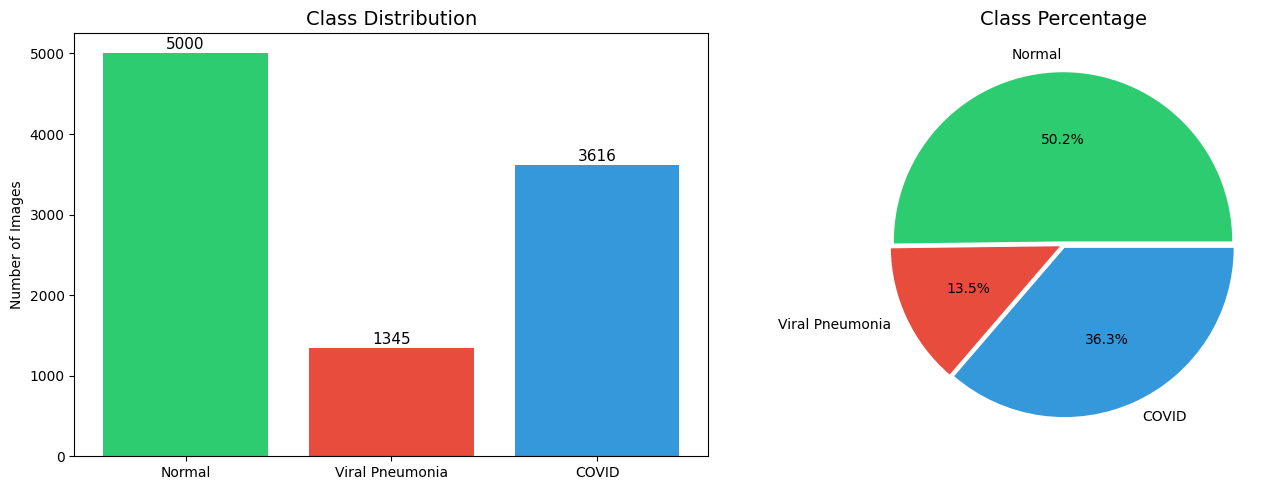

In [18]:
# Plot class distribution
class_names = ['Normal', 'Viral Pneumonia', 'COVID']
class_counts = [normal_count, pneumonia_count, covid_count]
colors = ['#2ecc71', '#e74c3c', '#3498db']

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Bar plot
bars = ax[0].bar(class_names, class_counts, color=colors)
ax[0].set_title('Class Distribution', fontsize=14)
ax[0].set_ylabel('Number of Images')
for bar, count in zip(bars, class_counts):
    ax[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 50,
               str(count), ha='center', fontsize=11)

# Pie chart
ax[1].pie(class_counts, labels=class_names, autopct='%1.1f%%',
          colors=colors, explode=[0.02, 0.02, 0.02])
ax[1].set_title('Class Percentage', fontsize=14)

plt.tight_layout()
plt.show()

#### Sample Images Visualization

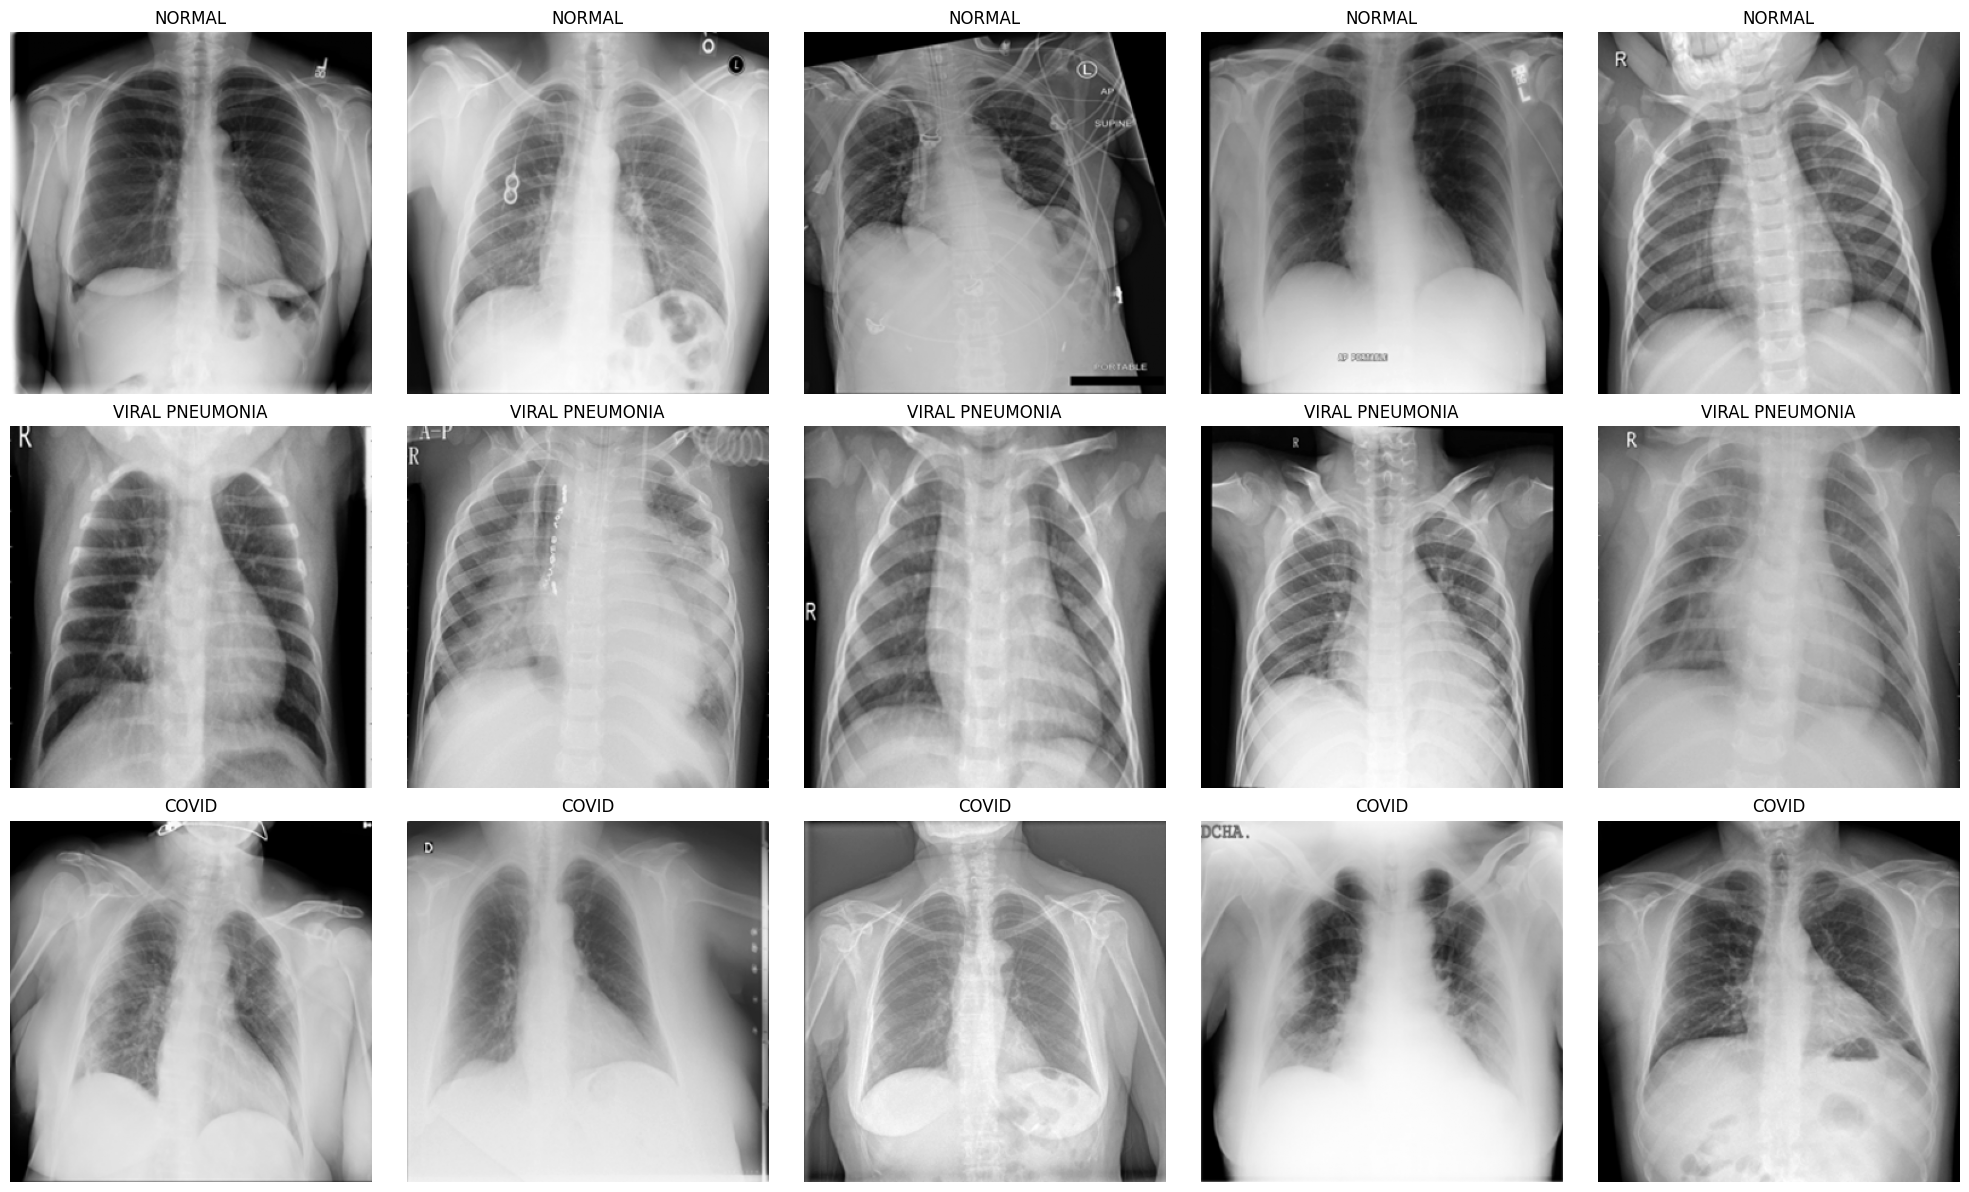

In [19]:
# Get samples for each class
normal_samples = (dataset[dataset["label"] == 0]["image"].iloc[:5]).tolist()
pneumonia_samples = (dataset[dataset["label"] == 1]["image"].iloc[:5]).tolist()
covid_samples = (dataset[dataset["label"] == 2]["image"].iloc[:5]).tolist()

# Plot the data
f, ax = plt.subplots(3, 5, figsize=(20, 12))

for i in range(5):
    # Normal
    img = imread(normal_samples[i])
    ax[0, i].imshow(img, cmap='gray')
    ax[0, i].set_title("NORMAL")
    ax[0, i].axis('off')

    # Viral Pneumonia
    img = imread(pneumonia_samples[i])
    ax[1, i].imshow(img, cmap='gray')
    ax[1, i].set_title("VIRAL PNEUMONIA")
    ax[1, i].axis('off')

    # COVID
    img = imread(covid_samples[i])
    ax[2, i].imshow(img, cmap='gray')
    ax[2, i].set_title("COVID")
    ax[2, i].axis('off')

plt.tight_layout()
plt.show()

## C. DATA PREPROCESSING

### Setting Parameters

In [20]:
# Image parameters
IMG_SIZE = 150  # Resize images to 150x150
NUM_CLASSES = 3  # Normal, Viral Pneumonia, COVID

# Class names for visualization
CLASS_NAMES = ['Normal', 'Viral Pneumonia', 'COVID']

# Random seed for reproducibility
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

### Loading and Preprocessing Images

In [21]:
# Convert image paths to string format
dataset['image'] = dataset['image'].astype(str)

# Lists to store images and labels
X = []
y = []

def apply_filter(img):
      if img.max() <= 1.0:
        img = (img * 255).astype(np.uint8)
      elif img.dtype != np.uint8:
        img = img.astype(np.uint8)
    # ----------------------------------------------------------
    # CLAHE
    # Migliora contrasto e riduce rumore
    # ----------------------------------------------------------
      clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
      img = clahe.apply(img)

      return img

# ============================================================

print("Loading images with filtering...")
for idx, row in dataset.iterrows():
    if idx % 1000 == 0:
        print(f"Processed {idx}/{len(dataset)} images...")

    # Read image in grayscale
    img = cv2.imread(row['image'], cv2.IMREAD_GRAYSCALE)

    # Apply filtering BEFORE resize
    img = apply_filter(img)

    # Resize image
    img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))

    # Append to lists
    X.append(img)
    y.append(row['label'])

print(f"Processed {len(dataset)}/{len(dataset)} images... Done!")

Loading images with filtering...
Processed 0/9961 images...
Processed 1000/9961 images...
Processed 2000/9961 images...
Processed 3000/9961 images...
Processed 4000/9961 images...
Processed 5000/9961 images...
Processed 6000/9961 images...
Processed 7000/9961 images...
Processed 8000/9961 images...
Processed 9000/9961 images...
Processed 9961/9961 images... Done!


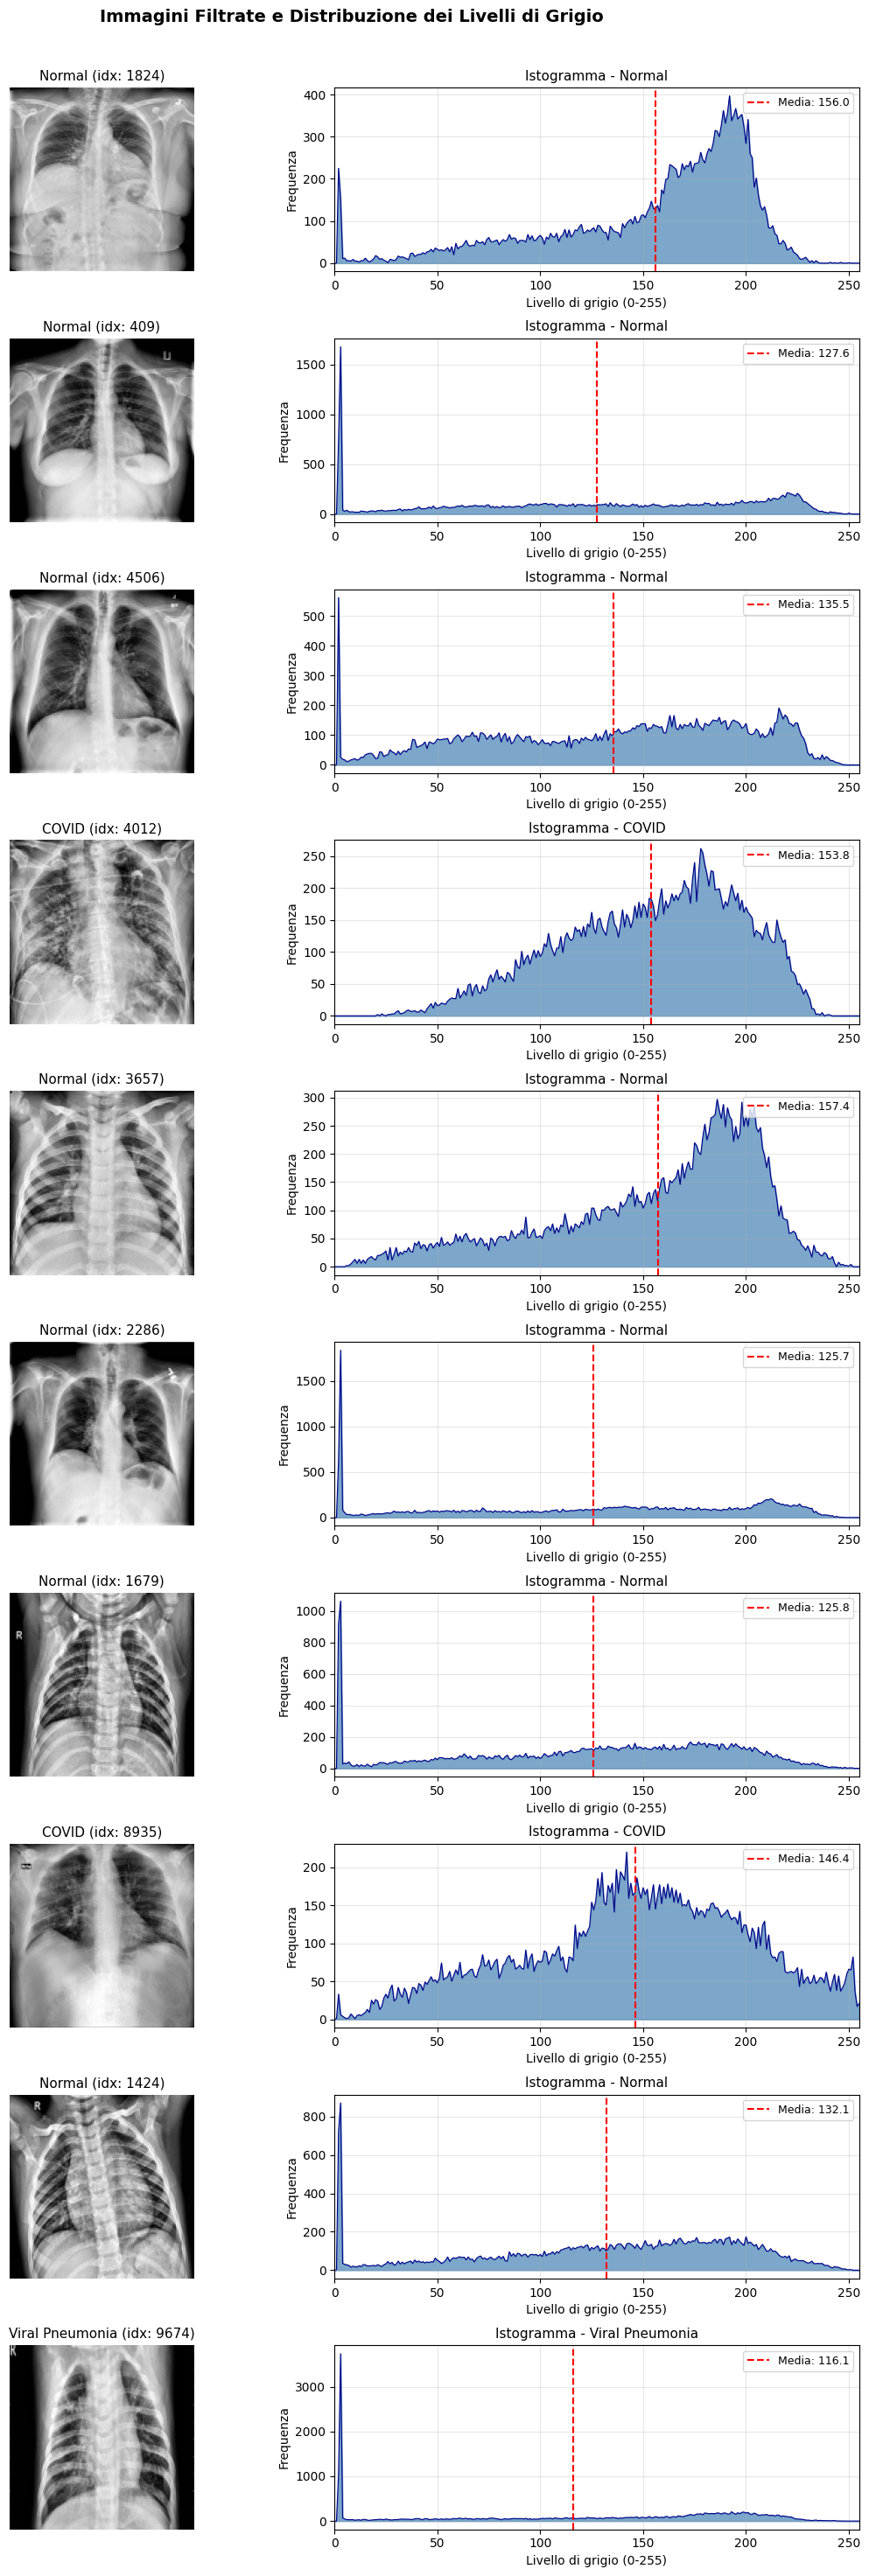

In [22]:
# ============================================================
# VISUALIZZAZIONE ISTOGRAMMI - Campione di 10 immagini random
# ============================================================

import random

# Numero di immagini da visualizzare
N_SAMPLES = 10

# Seleziona indici random
random.seed(42)  # Per riproducibilità
random_indices = random.sample(range(len(X)), N_SAMPLES)

# Crea figura con 2 colonne: immagine | istogramma
fig, axes = plt.subplots(N_SAMPLES, 2, figsize=(12, 3 * N_SAMPLES))

# Titolo generale
fig.suptitle('Immagini Filtrate e Distribuzione dei Livelli di Grigio', fontsize=14, fontweight='bold')

for i, idx in enumerate(random_indices):
    # Estrai immagine (rimuovi dimensione canale se presente)
    img = X[idx].squeeze()
    label = y[idx]

    # Colonna 1: Immagine
    axes[i, 0].imshow(img, cmap='gray')
    axes[i, 0].set_title(f'{CLASS_NAMES[label]} (idx: {idx})', fontsize=11)
    axes[i, 0].axis('off')

    # Colonna 2: Istogramma
    # Converti in range 0-255 per l'istogramma se normalizzato
    if img.max() <= 1.0:
        img_hist = (img * 255).astype(np.uint8)
    else:
        img_hist = img.astype(np.uint8)

    # Calcola istogramma
    hist = cv2.calcHist([img_hist], [0], None, [256], [0, 256])

    # Plot istogramma
    axes[i, 1].fill_between(range(256), hist.flatten(), alpha=0.7, color='steelblue')
    axes[i, 1].plot(hist, color='darkblue', linewidth=0.8)
    axes[i, 1].set_xlim([0, 255])
    axes[i, 1].set_xlabel('Livello di grigio (0-255)')
    axes[i, 1].set_ylabel('Frequenza')
    axes[i, 1].set_title(f'Istogramma - {CLASS_NAMES[label]}', fontsize=11)
    axes[i, 1].grid(True, alpha=0.3)

    # Aggiungi statistiche
    mean_val = np.mean(img_hist)
    std_val = np.std(img_hist)
    axes[i, 1].axvline(mean_val, color='red', linestyle='--', linewidth=1.5, label=f'Media: {mean_val:.1f}')
    axes[i, 1].legend(loc='upper right', fontsize=9)

plt.tight_layout()
plt.subplots_adjust(top=0.95)
plt.show()



In [23]:
# Convert to numpy arrays
X = np.array(X)
y = np.array(y)

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (9961, 150, 150)
y shape: (9961,)


In [24]:
# Reshape for CNN (add channel dimension)
X = X.reshape(-1, IMG_SIZE, IMG_SIZE, 1)

# Normalize pixel values to [0, 1]
X = X.astype('float32') / 255.0

print("X shape after reshape:", X.shape)
print("X min:", X.min(), "X max:", X.max())

X shape after reshape: (9961, 150, 150, 1)
X min: 0.0 X max: 1.0


### Data Augmentation

In [25]:
# ImageDataGenerator for data augmentation during training
image_generator = ImageDataGenerator(
    rotation_range=20,
    width_shift_range=0.15,
    height_shift_range=0.15,
    shear_range=0.15,
    zoom_range=0.15,
    horizontal_flip=True,
    fill_mode='nearest'
)

print("Data augmentation configured!")

Data augmentation configured!


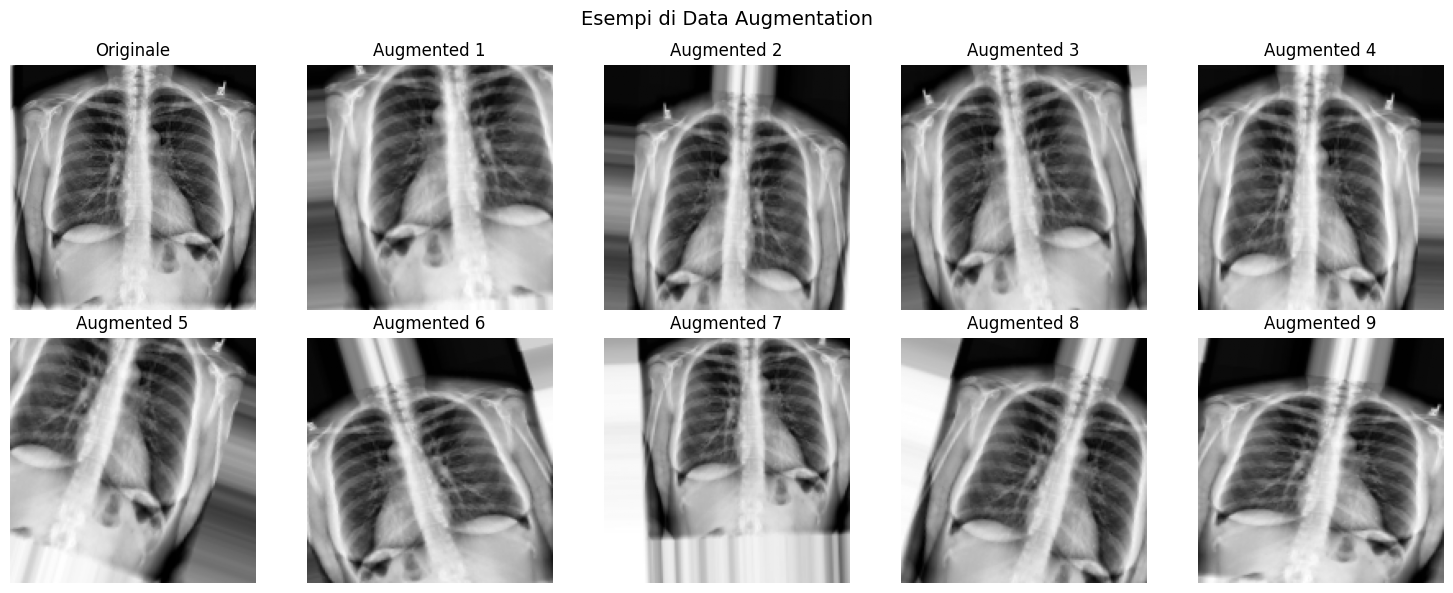

In [26]:
# Visualizza esempi di data augmentation
sample_img = X[0].reshape(1, IMG_SIZE, IMG_SIZE, 1)

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
axes = axes.flatten()

# Immagine originale
axes[0].imshow(X[0].squeeze(), cmap='gray')
axes[0].set_title('Originale')
axes[0].axis('off')

# Genera 9 versioni augmentate
aug_iter = image_generator.flow(sample_img, batch_size=1)
for i in range(1, 10):
    aug_img = next(aug_iter)[0].squeeze()
    axes[i].imshow(aug_img, cmap='gray')
    axes[i].set_title(f'Augmented {i}')
    axes[i].axis('off')

plt.suptitle('Esempi di Data Augmentation', fontsize=14)
plt.tight_layout()
plt.show()

## D. DATA MODELLING

### D.1 Building CNN Model

In [27]:
def build_model():
    """
    Build CNN model for multi-class classification.
    Architecture based on the example notebook.
    """
    model = Sequential()

    # Block 1
    model.add(Input(shape=(150, 150, 1)))
    model.add(Conv2D(32, (3,3), strides=1, padding='same', activation='relu'))
    model.add(BatchNormalization())
    model.add(MaxPool2D((2,2), strides=2, padding='same'))

    # Block 2
    model.add(Conv2D(64, (3,3), strides=1, padding='same', activation='relu'))
    model.add(Dropout(0.1))
    model.add(BatchNormalization())
    model.add(MaxPool2D((2,2), strides=2, padding='same'))

    # Block 3
    model.add(Conv2D(64, (3,3), strides=1, padding='same', activation='relu'))
    model.add(BatchNormalization())
    model.add(MaxPool2D((2,2), strides=2, padding='same'))

    # Block 4
    model.add(Conv2D(128, (3,3), strides=1, padding='same', activation='relu'))
    model.add(Dropout(0.2))
    model.add(BatchNormalization())
    model.add(MaxPool2D((2,2), strides=2, padding='same'))

    # Block 5
    model.add(Conv2D(256, (3,3), strides=1, padding='same', activation='relu'))
    model.add(Dropout(0.2))
    model.add(BatchNormalization())
    model.add(MaxPool2D((2,2), strides=2, padding='same'))

    # Classifier
    model.add(Flatten())
    model.add(Dense(units=128, activation='relu'))
    model.add(Dropout(0.2))

    # Output layer: 3 classes with softmax
    model.add(Dense(units=NUM_CLASSES, activation='softmax'))

    # Compile
    model.compile(
        optimizer='adamw',
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

    return model

# Build and show model summary
model = build_model()
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 150, 150, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 150, 150, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 75, 75, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 75, 75, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 75, 75, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 75, 75, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 38, 38, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 38, 38, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 38, 38, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 19, 19, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 19, 19, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 19, 19, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 19, 19, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 10, 10, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 10, 10, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 10, 10, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 10, 10, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 5, 5, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6400)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       819,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴─────────────

 Total params: 1,246,659 (4.76 MB)

 Trainable params: 1,245,571 (4.75 MB)

 Non-trainable params: 1,088 (4.25 KB)

### D.2 Class Weights (for imbalanced data)

In [28]:
def compute_class_weights(y):
    """
    Compute class weights to handle class imbalance.
    Formula: weight[i] = n_samples / (n_classes * n_samples_class_i)
    """
    unique, counts = np.unique(y, return_counts=True)
    n_samples = len(y)
    n_classes = len(unique)

    class_weights = {}
    for cls, count in zip(unique, counts):
        class_weights[cls] = n_samples / (n_classes * count)

    return class_weights

# Compute weights for full dataset
class_weights = compute_class_weights(y)
print("Class weights:")
for cls, weight in class_weights.items():
    print(f"  {CLASS_NAMES[cls]}: {weight:.3f}")

Class weights:
  Normal: 0.664
  Viral Pneumonia: 2.469
  COVID: 0.918


### D.3 Nested K-Fold Cross-Validation

La **Nested Cross-Validation** utilizza due loop:
- **Outer loop (3 fold)**: Per valutare le performance finali
- **Inner loop (3 fold)**: Per ottimizzare gli iperparametri

Questo garantisce una stima non distorta delle performance.

In [29]:
# Callbacks
def get_callbacks():
    early_stop = EarlyStopping(
        monitor='val_loss',
        patience=7,
        restore_best_weights=True,
        verbose=1
    )

    learning_rate_reduction = ReduceLROnPlateau(
        monitor='val_loss',
        patience=4,
        verbose=1,
        factor=0.3,
        min_lr=0.000001
    )

    return [early_stop, learning_rate_reduction]

In [30]:
# Nested Cross-Validation parameters
N_OUTER_FOLDS = 3
N_INNER_FOLDS = 3
EPOCHS = 25

# Hyperparameter grid for optimization
BATCH_SIZES = [16, 32, 64]  # Batch sizes to test in inner loop

# Initialize K-Fold
outer_cv = StratifiedKFold(n_splits=N_OUTER_FOLDS, shuffle=True, random_state=SEED)
inner_cv = StratifiedKFold(n_splits=N_INNER_FOLDS, shuffle=True, random_state=SEED)

# Storage for results
results = {
    'accuracy': [],
    'precision': [],
    'recall': [],
    'f1_macro': [],
    'confusion_matrices': [],
    'histories': [],
    'best_batch_sizes': []}

print("="*60)
print("NESTED K-FOLD CROSS-VALIDATION")
print(f"Outer folds: {N_OUTER_FOLDS}, Inner folds: {N_INNER_FOLDS}")
print("="*60)

NESTED K-FOLD CROSS-VALIDATION
Outer folds: 3, Inner folds: 3


In [ ]:
# NESTED CROSS-VALIDATION LOOP WITH BATCH SIZE OPTIMIZATION

for outer_fold, (train_val_idx, test_idx) in enumerate(outer_cv.split(X, y)):
    print(f"\n{'='*60}")
    print(f"OUTER FOLD {outer_fold + 1}/{N_OUTER_FOLDS}")
    print(f"{'='*60}")
    print(f"Train+Val: {len(train_val_idx)} samples, Test: {len(test_idx)} samples")

    # Split data
    X_train_val = X[train_val_idx]
    y_train_val = y[train_val_idx]
    X_test = X[test_idx]
    y_test = y[test_idx]

    # ===== INNER LOOP: HYPERPARAMETER OPTIMIZATION =====
    print(f"\n  Inner Cross-Validation for Batch Size Optimization...")

    # Store scores for each batch size
    batch_size_scores = {bs: [] for bs in BATCH_SIZES}

    for inner_fold, (train_idx, val_idx) in enumerate(inner_cv.split(X_train_val, y_train_val)):
        print(f"\n    Inner fold {inner_fold + 1}/{N_INNER_FOLDS}")

        # Split
        X_train = X_train_val[train_idx]
        y_train = y_train_val[train_idx]
        X_val = X_train_val[val_idx]
        y_val = y_train_val[val_idx]

        # Convert to categorical
        y_train_cat = to_categorical(y_train, NUM_CLASSES)
        y_val_cat = to_categorical(y_val, NUM_CLASSES)

        # Class weights
        fold_weights = compute_class_weights(y_train)

        # Test each batch size
        for batch_size in BATCH_SIZES:
            print(f"      Testing batch_size={batch_size}...", end="")

            # Build and train model
            model = build_model()
            callbacks = get_callbacks()

            history = model.fit(
                image_generator.flow(X_train, y_train_cat, batch_size=batch_size),
                epochs=EPOCHS,
                validation_data=(X_val, y_val_cat),
                class_weight=fold_weights,
                callbacks=callbacks,
                verbose=0
            )

            # Evaluate
            val_loss, val_acc = model.evaluate(X_val, y_val_cat, verbose=0)
            batch_size_scores[batch_size].append(val_acc)
            print(f" Val accuracy: {val_acc:.4f}")

            # Clear memory
            tf.keras.backend.clear_session()

    # Find best batch size based on mean validation accuracy
    print(f"\n  Batch Size Optimization Results:")
    print(f"  {'-'*50}")
    best_batch_size = None
    best_mean_score = 0

    for bs, scores in batch_size_scores.items():
        mean_score = np.mean(scores)
        std_score = np.std(scores)
        print(f"    Batch Size {bs}: {mean_score:.4f} (+/- {std_score:.4f})")
        if mean_score > best_mean_score:
            best_mean_score = mean_score
            best_batch_size = bs

    print(f"  {'-'*50}")
    print(f"  *** Best Batch Size: {best_batch_size} (accuracy: {best_mean_score:.4f}) ***")
    results['best_batch_sizes'].append(best_batch_size)

    # ===== FINAL TRAINING WITH BEST BATCH SIZE =====
    print(f"\n  Final training with best batch_size={best_batch_size}...")

    # Split train_val in train e validation per il training finale

    X_train_final, X_val_final, y_train_final, y_val_final = train_test_split(
        X_train_val, y_train_val,
        test_size=0.15,  # 15% per validation interna
        stratify=y_train_val,
        random_state=SEED
    )

    # Convert to categorical
    y_train_final_cat = to_categorical(y_train_final, NUM_CLASSES)
    y_val_final_cat = to_categorical(y_val_final, NUM_CLASSES)
    y_test_cat = to_categorical(y_test, NUM_CLASSES)

    # Class weights (calcolati sul train finale)
    final_weights = compute_class_weights(y_train_final)

    # Build and train final model with best batch size
    final_model = build_model()
    final_callbacks = get_callbacks()

    history = final_model.fit(
        image_generator.flow(X_train_final, y_train_final_cat, batch_size=best_batch_size),
        epochs=EPOCHS,
        validation_data=(X_val_final, y_val_final_cat),
        class_weight=final_weights,
        callbacks=final_callbacks,
        verbose=1
    )

    # Valutazione sul VERO test esterno (mai visto durante il training)
    y_pred_proba = final_model.predict(X_test)
    y_pred = np.argmax(y_pred_proba, axis=1)

    # Metrics - queste sono le metriche "vere" sul test esterno
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, average='macro')
    recall = recall_score(y_test, y_pred, average='macro')
    f1 = f1_score(y_test, y_pred, average='macro')
    cm = confusion_matrix(y_test, y_pred)

    # Save results
    results['accuracy'].append(accuracy)
    results['precision'].append(precision)
    results['recall'].append(recall)
    results['f1_macro'].append(f1)
    results['confusion_matrices'].append(cm)
    results['histories'].append(history.history)

    # Print results
    print(f"\n  OUTER FOLD {outer_fold + 1} RESULTS:")
    print(f"  {'-'*40}")
    print(f"    Best Batch Size:   {best_batch_size}")
    print(f"    Accuracy:          {accuracy:.4f}")
    print(f"    Precision (macro): {precision:.4f}")
    print(f"    Recall (macro):    {recall:.4f}")
    print(f"    F1-score (macro):  {f1:.4f}")

    # Classification Report
    print(f"\n  Classification Report:")
    print(classification_report(y_test, y_pred, target_names=CLASS_NAMES))

    # Clear memory
    tf.keras.backend.clear_session()



OUTER FOLD 1/3
Train+Val: 6640 samples, Test: 3321 samples

  Inner Cross-Validation for Batch Size Optimization...

    Inner fold 1/3
      Testing batch_size=16...

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()



Epoch 8: ReduceLROnPlateau reducing learning rate to 0.0003000000142492354.
Epoch 11: early stopping
Restoring model weights from the end of the best epoch: 4.
 Val accuracy: 0.7692
      Testing batch_size=32...
Epoch 19: ReduceLROnPlateau reducing learning rate to 0.0003000000142492354.
Epoch 22: early stopping
Restoring model weights from the end of the best epoch: 15.
 Val accuracy: 0.8523
      Testing batch_size=64...
Epoch 8: ReduceLROnPlateau reducing learning rate to 0.0003000000142492354.

Epoch 16: ReduceLROnPlateau reducing learning rate to 9.000000427477062e-05.

Epoch 21: ReduceLROnPlateau reducing learning rate to 2.700000040931627e-05.
Epoch 24: early stopping
Restoring model weights from the end of the best epoch: 17.
 Val accuracy: 0.8690

    Inner fold 2/3
      Testing batch_size=16...
Epoch 18: ReduceLROnPlateau reducing learning rate to 0.0003000000142492354.
Epoch 21: early stopping
Restoring model weights from the end of the best epoch: 14.
 Val accuracy: 0.87

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/25
89/89 ━━━━━━━━━━━━━━━━━━━━ 28s 206ms/step - accuracy: 0.5392 - loss: 1.6525 - val_accuracy: 0.3635 - val_loss: 9.4504 - learning_rate: 0.0010
Epoch 2/25
89/89 ━━━━━━━━━━━━━━━━━━━━ 9s 106ms/step - accuracy: 0.6734 - loss: 0.5781 - val_accuracy: 0.3635 - val_loss: 8.7739 - learning_rate: 0.0010
Epoch 3/25
89/89 ━━━━━━━━━━━━━━━━━━━━ 9s 106ms/step - accuracy: 0.7382 - loss: 0.5096 - val_accuracy: 0.3624 - val_loss: 1.2090 - learning_rate: 0.0010
Epoch 4/25
89/89 ━━━━━━━━━━━━━━━━━━━━ 10s 107ms/step - accuracy: 0.7696 - loss: 0.4384 - val_accuracy: 0.3645 - val_loss: 2.5671 - learning_rate: 0.0010
Epoch 5/25
89/89 ━━━━━━━━━━━━━━━━━━━━ 10s 107ms/step - accuracy: 0.7823 - loss: 0.4230 - val_accuracy: 0.4428 - val_loss: 1.6448 - learning_rate: 0.0010
Epoch 6/25
89/89 ━━━━━━━━━━━━━━━━━━━━ 10s 107ms/step - accuracy: 0.7991 - loss: 0.3990 - val_accuracy: 0.5281 - val_loss: 1.6047 - learning_rate: 0.0010
Epoch 7/25
89/89 ━━━━━━━━━━━━━━━━━━━━ 10s 106ms/step - accuracy: 0.8152 - loss: 0.38

...

353/353 ━━━━━━━━━━━━━━━━━━━━ 27s 49ms/step - accuracy: 0.5524 - loss: 1.5954 - val_accuracy: 0.4283 - val_loss: 1.9416 - learning_rate: 0.0010
Epoch 2/25
353/353 ━━━━━━━━━━━━━━━━━━━━ 10s 28ms/step - accuracy: 0.6570 - loss: 0.5939 - val_accuracy: 0.6640 - val_loss: 0.7867 - learning_rate: 0.0010
Epoch 3/25
353/353 ━━━━━━━━━━━━━━━━━━━━ 10s 28ms/step - accuracy: 0.7098 - loss: 0.5216 - val_accuracy: 0.6299 - val_loss: 0.8175 - learning_rate: 0.0010
Epoch 4/25
353/353 ━━━━━━━━━━━━━━━━━━━━ 10s 28ms/step - accuracy: 0.7271 - loss: 0.4913 - val_accuracy: 0.6158 - val_loss: 0.6682 - learning_rate: 0.0010
Epoch 5/25
353/353 ━━━━━━━━━━━━━━━━━━━━ 10s 28ms/step - accuracy: 0.7395 - loss: 0.4735 - val_accuracy: 0.3631 - val_loss: 6.4855 - learning_rate: 0.0010
Epoch 6/25
353/353 ━━━━━━━━━━━━━━━━━━━━ 10s 28ms/step - accuracy: 0.7826 - loss: 0.4158 - val_accuracy: 0.7111 - val_loss: 0.5687 - learning_rate: 0.0010
Epoch 7/25
353/353 ━━━━━━━━━━━━━━━━━━━━ 10s 28ms/step - accuracy: 0.7910 - loss: 0.4131

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()



Epoch 8: ReduceLROnPlateau reducing learning rate to 0.0003000000142492354.

Epoch 13: ReduceLROnPlateau reducing learning rate to 9.000000427477062e-05.
Epoch 16: early stopping
Restoring model weights from the end of the best epoch: 9.
 Val accuracy: 0.8437
      Testing batch_size=32...
Epoch 10: ReduceLROnPlateau reducing learning rate to 0.0003000000142492354.

Epoch 16: ReduceLROnPlateau reducing learning rate to 9.000000427477062e-05.

Epoch 22: ReduceLROnPlateau reducing learning rate to 2.700000040931627e-05.
Epoch 25: early stopping
Restoring model weights from the end of the best epoch: 18.
 Val accuracy: 0.9228
      Testing batch_size=64...
Epoch 21: ReduceLROnPlateau reducing learning rate to 0.0003000000142492354.
Restoring model weights from the end of the best epoch: 22.
 Val accuracy: 0.9228

    Inner fold 2/3
      Testing batch_size=16...
Epoch 9: ReduceLROnPlateau reducing learning rate to 0.0003000000142492354.

Epoch 18: ReduceLROnPlateau reducing learning rate

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


353/353 ━━━━━━━━━━━━━━━━━━━━ 28s 51ms/step - accuracy: 0.5742 - loss: 1.4303 - val_accuracy: 0.3671 - val_loss: 2.6459 - learning_rate: 0.0010
Epoch 2/25
353/353 ━━━━━━━━━━━━━━━━━━━━ 10s 29ms/step - accuracy: 0.6830 - loss: 0.5980 - val_accuracy: 0.6359 - val_loss: 0.6500 - learning_rate: 0.0010
Epoch 3/25
353/353 ━━━━━━━━━━━━━━━━━━━━ 10s 28ms/step - accuracy: 0.7068 - loss: 0.5542 - val_accuracy: 0.5567 - val_loss: 0.8396 - learning_rate: 0.0010
Epoch 4/25
353/353 ━━━━━━━━━━━━━━━━━━━━ 10s 28ms/step - accuracy: 0.7528 - loss: 0.5111 - val_accuracy: 0.7262 - val_loss: 0.5917 - learning_rate: 0.0010
Epoch 5/25
353/353 ━━━━━━━━━━━━━━━━━━━━ 10s 28ms/step - accuracy: 0.7807 - loss: 0.4244 - val_accuracy: 0.4764 - val_loss: 2.3688 - learning_rate: 0.0010
Epoch 6/25
353/353 ━━━━━━━━━━━━━━━━━━━━ 10s 29ms/step - accuracy: 0.7811 - loss: 0.4201 - val_accuracy: 0.7192 - val_loss: 0.6404 - learning_rate: 0.0010
Epoch 7/25
353/353 ━━━━━━━━━━━━━━━━━━━━ 10s 28ms/step - accuracy: 0.7957 - loss: 0.4208

## E. RISULTATI

### E.1 Final Metrics

In [32]:
print("="*60)
print("FINAL RESULTS - NESTED CROSS-VALIDATION")
print("="*60)

print("\nPerformance (Mean +/- Std):")
print("-" * 50)
print(f"  Accuracy:          {np.mean(results['accuracy']):.4f} +/- {np.std(results['accuracy']):.4f}")
print(f"  Precision (macro): {np.mean(results['precision']):.4f} +/- {np.std(results['precision']):.4f}")
print(f"  Recall (macro):    {np.mean(results['recall']):.4f} +/- {np.std(results['recall']):.4f}")
print(f"  F1-score (macro):  {np.mean(results['f1_macro']):.4f} +/- {np.std(results['f1_macro']):.4f}")
print("-" * 50)

FINAL RESULTS - NESTED CROSS-VALIDATION

Performance (Mean +/- Std):
--------------------------------------------------
  Accuracy:          0.9175 +/- 0.0187
  Precision (macro): 0.9113 +/- 0.0247
  Recall (macro):    0.9269 +/- 0.0140
  F1-score (macro):  0.9176 +/- 0.0201
--------------------------------------------------


### E.2 Confusion Matrix

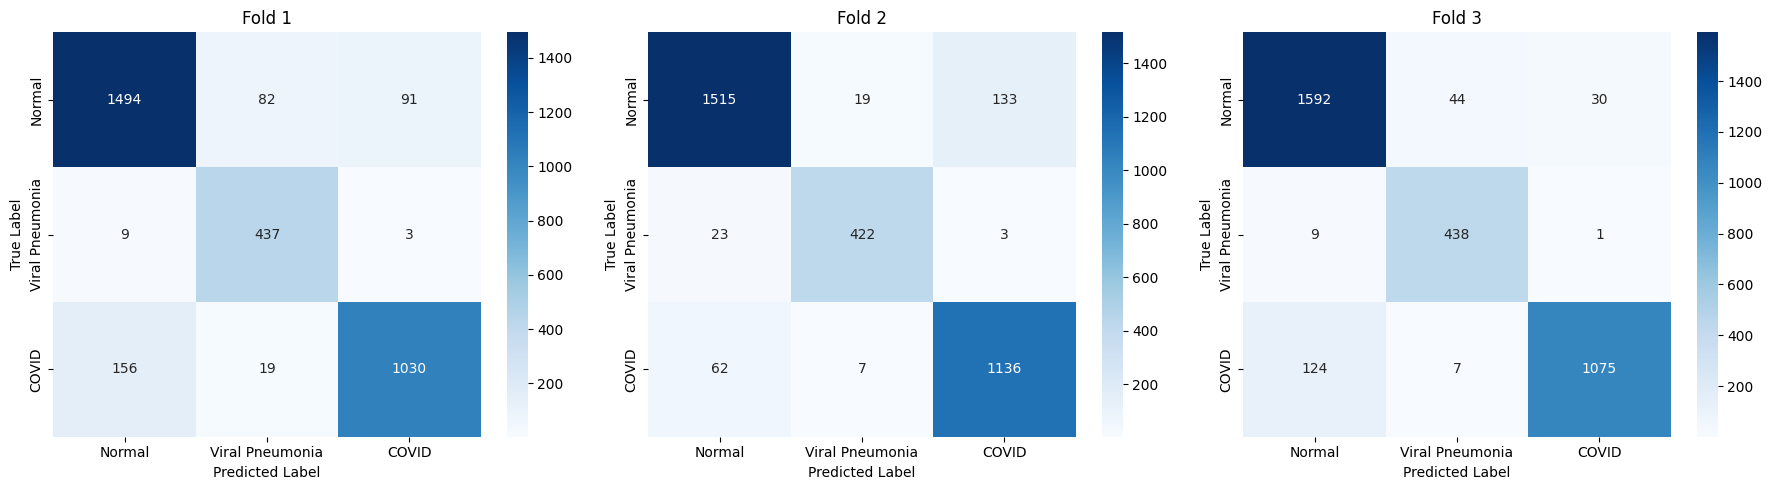

In [33]:
# Plot confusion matrix for each fold
fig, axes = plt.subplots(1, N_OUTER_FOLDS, figsize=(6*N_OUTER_FOLDS, 5))

for i, cm in enumerate(results['confusion_matrices']):
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=axes[i])
    axes[i].set_title(f'Fold {i+1}')
    axes[i].set_ylabel('True Label')
    axes[i].set_xlabel('Predicted Label')

plt.tight_layout()
plt.show()

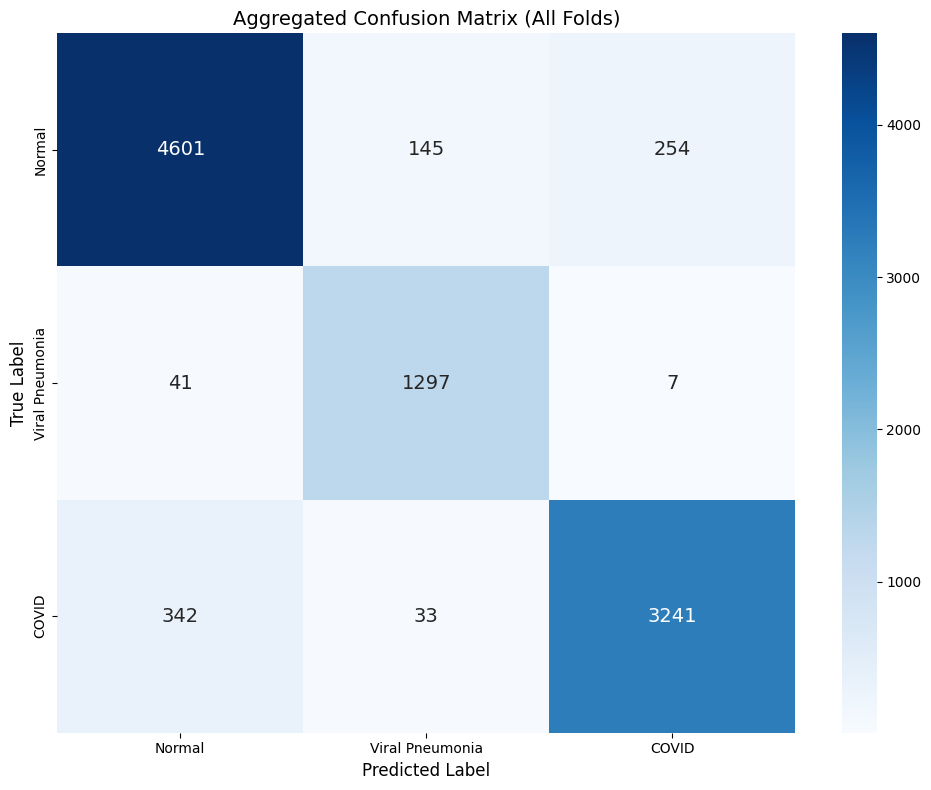

In [34]:
# Aggregated confusion matrix
total_cm = np.sum(results['confusion_matrices'], axis=0)

plt.figure(figsize=(10, 8))
sns.heatmap(total_cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
            annot_kws={'size': 14})
plt.title('Aggregated Confusion Matrix (All Folds)', fontsize=14)
plt.ylabel('True Label', fontsize=12)
plt.xlabel('Predicted Label', fontsize=12)
plt.tight_layout()
plt.show()

### E.3 Metrics per Fold

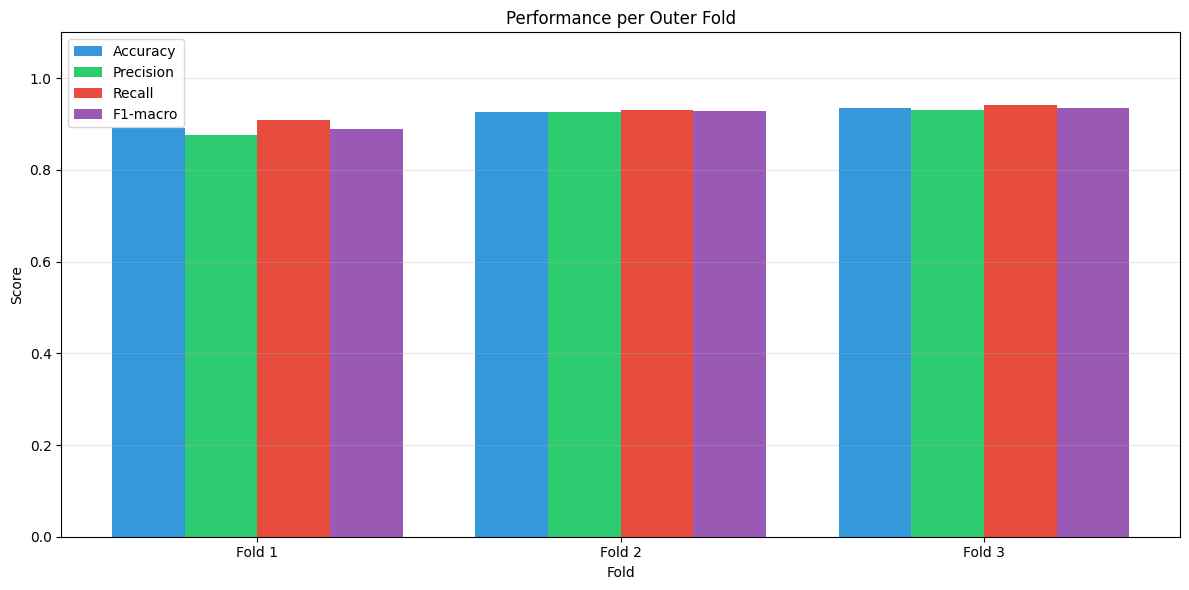

In [35]:
# Plot metrics per fold
fig, ax = plt.subplots(figsize=(12, 6))

x = np.arange(N_OUTER_FOLDS)
width = 0.2

ax.bar(x - 1.5*width, results['accuracy'], width, label='Accuracy', color='#3498db')
ax.bar(x - 0.5*width, results['precision'], width, label='Precision', color='#2ecc71')
ax.bar(x + 0.5*width, results['recall'], width, label='Recall', color='#e74c3c')
ax.bar(x + 1.5*width, results['f1_macro'], width, label='F1-macro', color='#9b59b6')

ax.set_ylabel('Score')
ax.set_xlabel('Fold')
ax.set_title('Performance per Outer Fold')
ax.set_xticks(x)
ax.set_xticklabels([f'Fold {i+1}' for i in range(N_OUTER_FOLDS)])
ax.legend()
ax.set_ylim(0, 1.1)
ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

### E.4 Training History

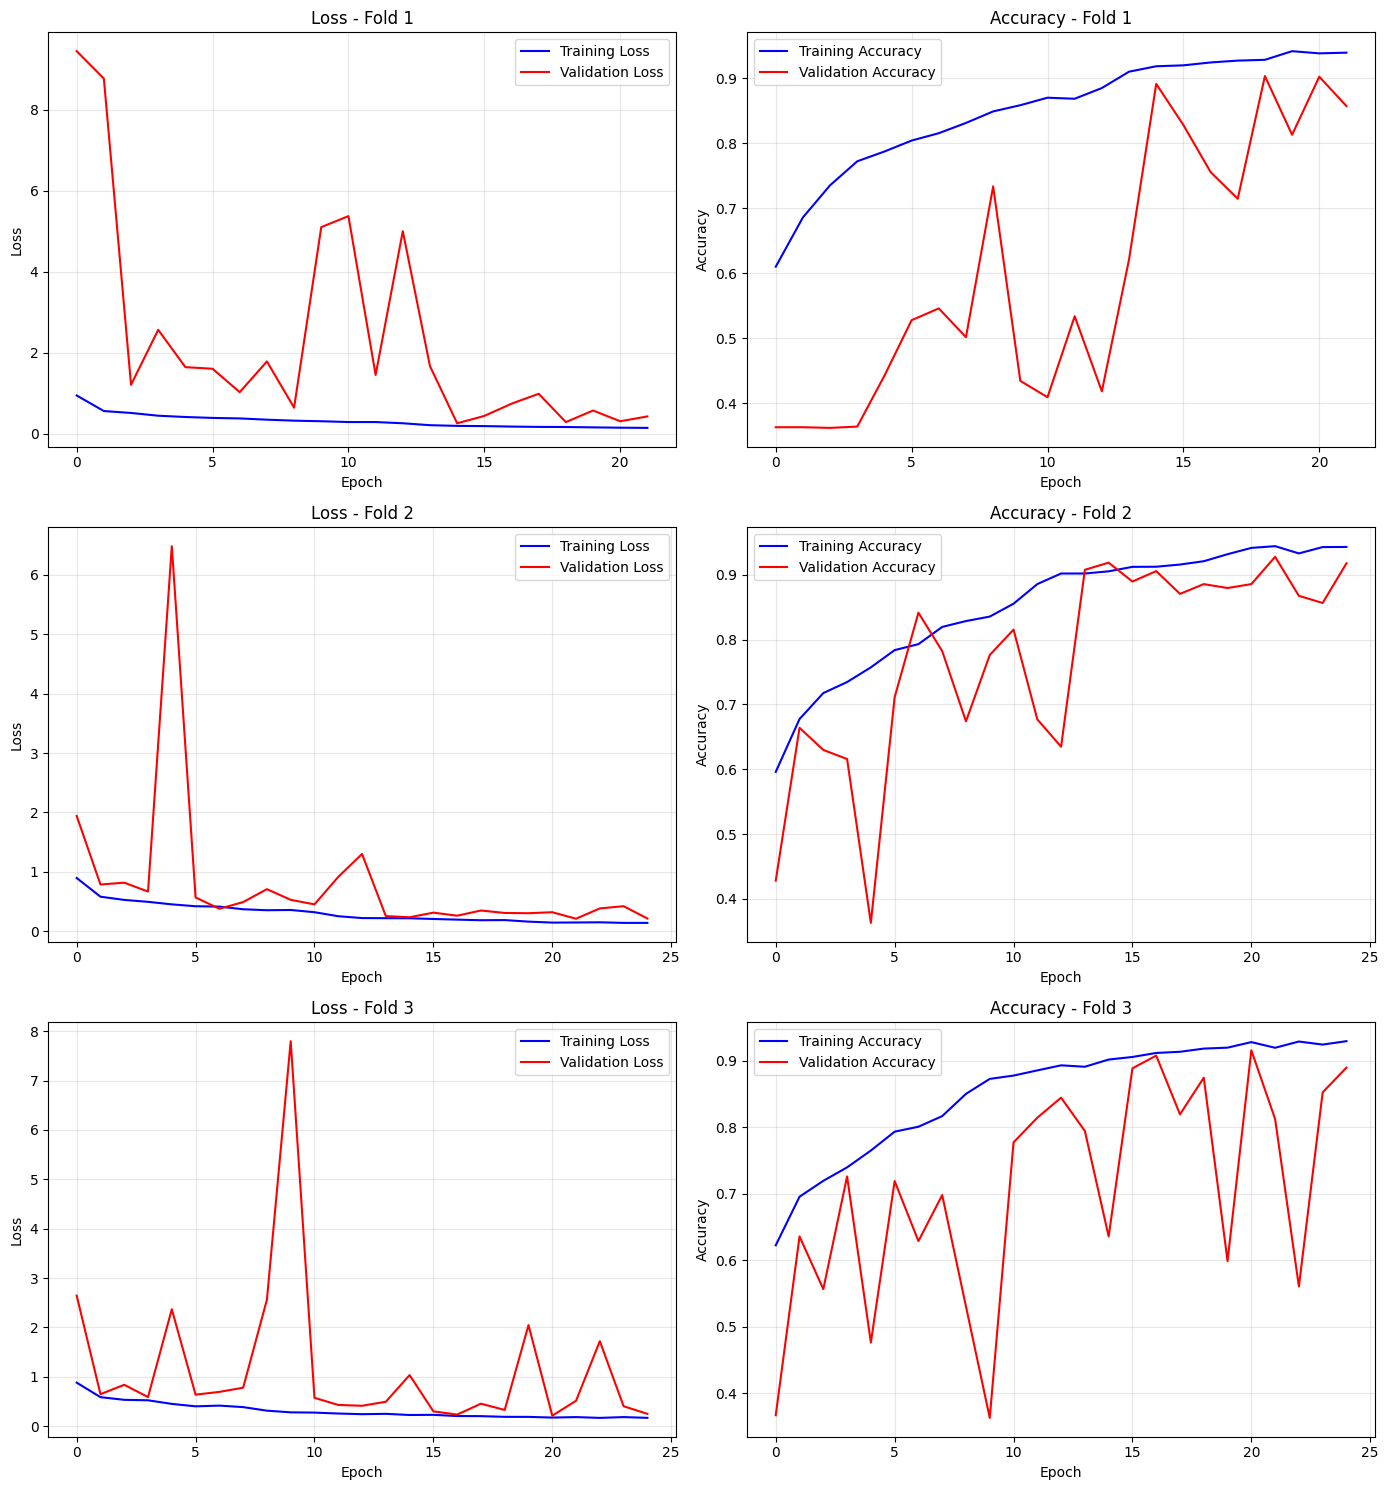

In [36]:
# Plot training history for each fold
fig, axes = plt.subplots(N_OUTER_FOLDS, 2, figsize=(14, 5*N_OUTER_FOLDS))

for fold, history in enumerate(results['histories']):
    # Loss
    axes[fold, 0].plot(history['loss'], label='Training Loss', color='blue')
    axes[fold, 0].plot(history['val_loss'], label='Validation Loss', color='red')
    axes[fold, 0].set_title(f'Loss - Fold {fold + 1}')
    axes[fold, 0].set_xlabel('Epoch')
    axes[fold, 0].set_ylabel('Loss')
    axes[fold, 0].legend()
    axes[fold, 0].grid(True, alpha=0.3)

    # Accuracy
    axes[fold, 1].plot(history['accuracy'], label='Training Accuracy', color='blue')
    axes[fold, 1].plot(history['val_accuracy'], label='Validation Accuracy', color='red')
    axes[fold, 1].set_title(f'Accuracy - Fold {fold + 1}')
    axes[fold, 1].set_xlabel('Epoch')
    axes[fold, 1].set_ylabel('Accuracy')
    axes[fold, 1].legend()
    axes[fold, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### E.5 Summary Table

In [37]:
print("\n" + "="*60)
print("SUMMARY TABLE (for report)")
print("="*60)
print("\n| Metric             | Mean   | Std    |")
print("|--------------------+--------+--------|")
print(f"| Accuracy           | {np.mean(results['accuracy']):.4f} | {np.std(results['accuracy']):.4f} |")
print(f"| Precision (macro)  | {np.mean(results['precision']):.4f} | {np.std(results['precision']):.4f} |")
print(f"| Recall (macro)     | {np.mean(results['recall']):.4f} | {np.std(results['recall']):.4f} |")
print(f"| F1-score (macro)   | {np.mean(results['f1_macro']):.4f} | {np.std(results['f1_macro']):.4f} |")
print("="*60)


SUMMARY TABLE (for report)

| Metric             | Mean   | Std    |
|--------------------+--------+--------|
| Accuracy           | 0.9175 | 0.0187 |
| Precision (macro)  | 0.9113 | 0.0247 |
| Recall (macro)     | 0.9269 | 0.0140 |
| F1-score (macro)   | 0.9176 | 0.0201 |


## F. CONCLUSIONI

### Riepilogo:

1. **Dataset**: Radiografie toraciche con 3 classi (Normal, Viral Pneumonia, COVID)

2. **Preprocessing**:
   - Ridimensionamento a 150×150 pixel
   - Conversione in scala di grigi
   - Normalizzazione [0, 1]
   - CLAHE

3. **Data Augmentation**: Rotazione, traslazione, zoom, flip orizzontale

4. **Modello**: CNN con 5 blocchi convoluzionali

5. **Validazione**: Nested 3×3 Cross-Validation

6. **Gestione sbilanciamento**: Class weights

## G. RESOURCES

**Notebook Resources**

* COVID-19 Radiography Database

**Website Resources**

* https://www.tensorflow.org/api_docs/python/tf/keras/preprocessing/image/ImageDataGenerator
* https://keras.io/api/layers/convolution_layers/
* https://scikit-learn.org/stable/modules/cross_validation.html
* https://keras.io/api/optimizers/adamw/

